In [1]:
!pip install -q sentence-transformers transformers datasets scikit-learn seaborn
import pandas as pd

In [2]:
df = pd.read_csv("bias_clean.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head())

(10832, 7)
['url', 'topic', 'date', 'title', 'site', 'bias', 'page_text']
                                                 url         topic  \
0  https://www.npr.org/2021/01/01/952336030/what-...  general-news   
1  https://www.cbsnews.com/news/new-years-eve-gat...  general-news   
2  https://nypost.com/2020/12/31/heres-how-countr...  general-news   
3  https://www.theguardian.com/world/2020/dec/31/...   coronavirus   
4  https://www.foxnews.com/us/wis-hospital-intent...   coronavirus   

         date                                              title  \
0  2021-01-01  What Got Us Through 2020? For Many, It Was Hob...   
1  2020-12-31  New Year's Eve gatherings could accelerate COV...   
2  2020-12-31  Here’s how countries around the world are ring...   
3  2020-12-31  Wisconsin health worker 'deliberately spoiled ...   
4  2020-12-31  Wisconsin hospital employee 'intentionally' re...   

                   site           bias  \
0     NPR (Online News)   leaning-left   
1     CBS Ne

label
right            2986
leaning-left     2951
left             1930
leaning-right    1487
center           1478
Name: count, dtype: int64
unmapped: 0
(10825, 3)
label
left       4880
right      4468
neutral    1477
Name: count, dtype: int64


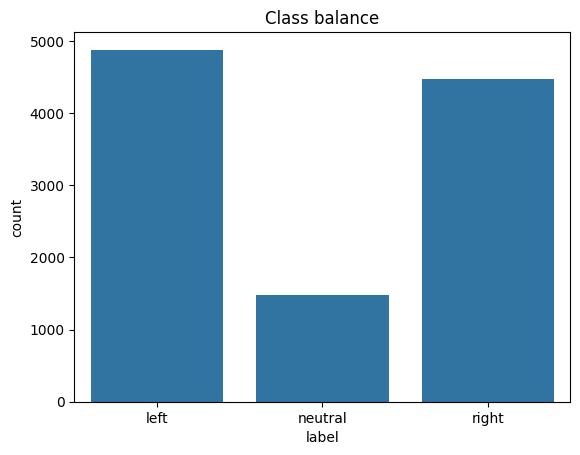

In [3]:
import re
import seaborn as sns
import matplotlib.pyplot as plt

# keep only what we need
data = df[["title", "bias", "site"]].copy()
data = data.rename(columns={"title": "headline", "bias": "label"})

print(data["label"].value_counts())

# merge 5 labels into 3
label_map = {
    "left": "left",
    "leaning-left": "left",
    "center": "neutral",
    "right": "right",
    "leaning-right": "right",
}
data["label"] = data["label"].map(label_map)
print("unmapped:", data["label"].isna().sum())

# drop missing / duplicate headlines
data = data.dropna(subset=["headline", "label"])
data = data.drop_duplicates(subset=["headline"])

def clean(text):
    text = re.sub(r"http\S+", "", text)       # links
    text = re.sub(r"\s+", " ", text)          # extra spaces
    return text.strip()

data["headline"] = data["headline"].apply(clean)

# very short headlines are mostly junk
data = data[data["headline"].str.split().str.len() >= 3]
data = data.reset_index(drop=True)

print(data.shape)
print(data["label"].value_counts())

sns.countplot(data=data, x="label", order=["left", "neutral", "right"])
plt.title("Class balance")
plt.show()

          count       mean       std  min   25%   50%   75%   max
label                                                            
left     4880.0  11.604713  3.306397  3.0   9.0  11.0  14.0  32.0
neutral  1477.0  10.390657  3.050122  3.0   8.0  10.0  12.0  27.0
right    4468.0  11.888541  3.395519  3.0  10.0  12.0  14.0  38.0


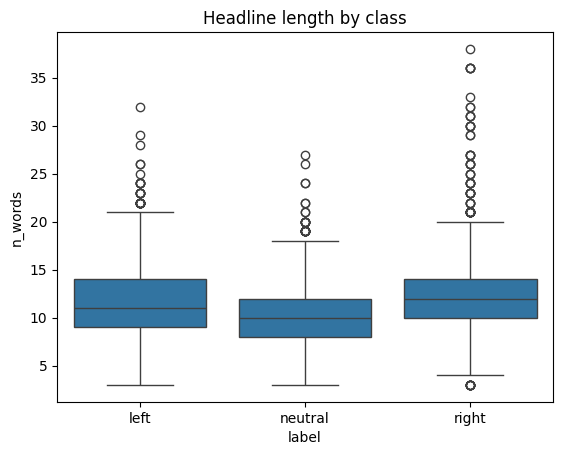

In [4]:
data["n_words"] = data["headline"].str.split().str.len()

print(data.groupby("label")["n_words"].describe())

sns.boxplot(data=data, x="label", y="n_words", order=["left", "neutral", "right"])
plt.title("Headline length by class")
plt.show()

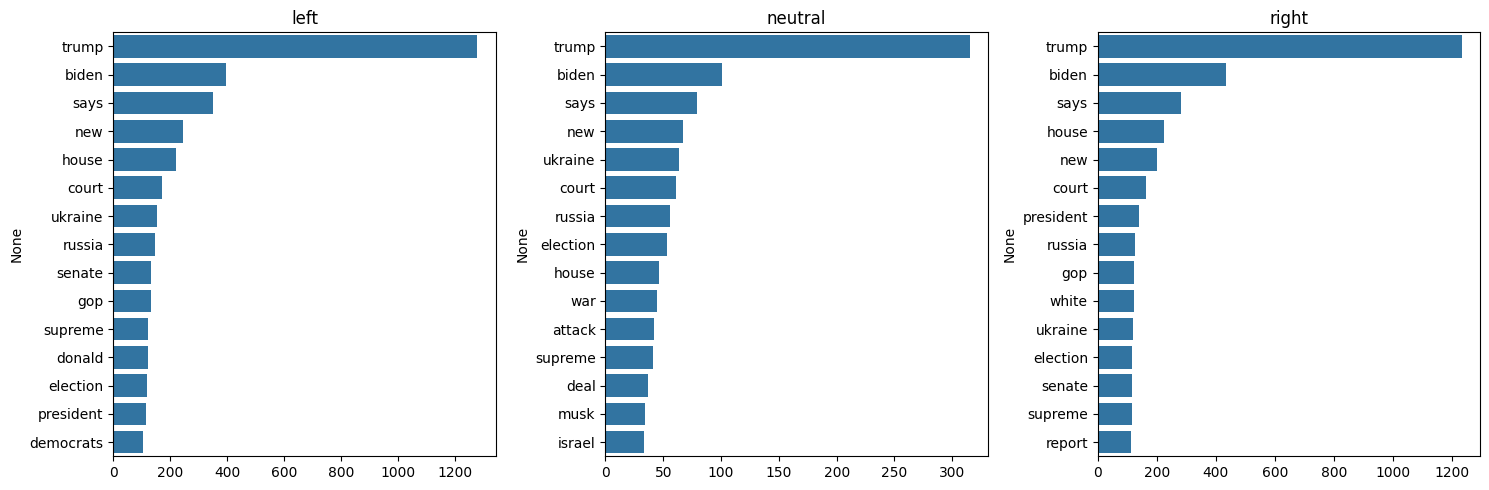

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

order = ["left", "neutral", "right"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, lab in zip(axes, order):
    texts = data.loc[data["label"] == lab, "headline"]
    cv = CountVectorizer(stop_words="english", lowercase=True)
    counts = cv.fit_transform(texts).sum(axis=0).A1
    words = pd.Series(counts, index=cv.get_feature_names_out()).nlargest(15)
    sns.barplot(x=words.values, y=words.index, ax=ax)
    ax.set_title(lab)

plt.tight_layout()
plt.show()

In [6]:
cv = CountVectorizer(stop_words="english", lowercase=True, min_df=20)
X = cv.fit_transform(data["headline"])
vocab = cv.get_feature_names_out()

left_mask = (data["label"] == "left").values
right_mask = (data["label"] == "right").values

# share of each class's headlines containing the word
left_rate = (X[left_mask] > 0).mean(axis=0).A1
right_rate = (X[right_mask] > 0).mean(axis=0).A1

diff = pd.Series(left_rate - right_rate, index=vocab)
print("More left:\n", diff.nlargest(15))
print("\nMore right:\n", diff.nsmallest(15))

More left:
 donald         0.011366
say            0.009824
says           0.009296
gaza           0.009285
joe            0.007239
republicans    0.006934
new            0.005928
ukraine        0.004924
won            0.004853
democratic     0.004667
make           0.004502
just           0.004480
covid          0.004175
right          0.003995
said           0.003985
dtype: float64

More right:
 biden         -0.016060
trump         -0.014279
admin         -0.011509
report        -0.009493
media         -0.009245
dems          -0.009123
president     -0.007545
announces     -0.007451
coronavirus   -0.007026
white         -0.006813
amid          -0.006449
house         -0.006320
harris        -0.006187
calls         -0.006095
illegal       -0.005917
dtype: float64


In [7]:
print("sites:", data["site"].nunique())

# how many classes does each site appear in?
site_classes = data.groupby("site")["label"].nunique()
print(site_classes.value_counts())

# top sites per class
print(data.groupby("label")["site"].value_counts().groupby(level=0).head(5))

sites: 297
label
1    297
Name: count, dtype: int64
label    site                     
left     CNN Digital                   901
         Associated Press              571
         NBC News Digital              400
         HuffPost                      375
         USA TODAY                     375
neutral  BBC News                      609
         Forbes                        198
         Christian Science Monitor      88
         Reason                         68
         Straight Arrow News            28
right    Fox News Digital             1706
         Washington Examiner           938
         Townhall                      321
         Fox Business                  282
         Breitbart News                257
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import StratifiedGroupKFold

# test sites are never seen in training
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(data, data["label"], groups=data["site"]))

train_df = data.iloc[train_idx].reset_index(drop=True)
test_df = data.iloc[test_idx].reset_index(drop=True)

print(len(train_df), len(test_df))
print(train_df["label"].value_counts(normalize=True).round(2))
print(test_df["label"].value_counts(normalize=True).round(2))
print("shared sites:", set(train_df["site"]) & set(test_df["site"]))

7999 2826
label
left       0.45
right      0.39
neutral    0.17
Name: proportion, dtype: float64
label
right      0.48
left       0.46
neutral    0.05
Name: proportion, dtype: float64
shared sites: set()


In [9]:
from sentence_transformers import SentenceTransformer

sbert = SentenceTransformer("all-MiniLM-L6-v2")
X_train = sbert.encode(train_df["headline"].tolist(), batch_size=64, show_progress_bar=True)
X_test = sbert.encode(test_df["headline"].tolist(), batch_size=64, show_progress_bar=True)
print(X_train.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

Batches:   0%|          | 0/45 [00:00<?, ?it/s]

(7999, 384)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, train_df["label"])
pred = clf.predict(X_test)

print(classification_report(test_df["label"], pred))
print("macro F1:", f1_score(test_df["label"], pred, average="macro"))

              precision    recall  f1-score   support

        left       0.44      0.31      0.37      1311
     neutral       0.07      0.44      0.12       148
       right       0.50      0.36      0.42      1367

    accuracy                           0.34      2826
   macro avg       0.34      0.37      0.30      2826
weighted avg       0.45      0.34      0.38      2826

macro F1: 0.302115910338457


In [11]:
import numpy as np
from sklearn.model_selection import train_test_split

X_all = sbert.encode(data["headline"].tolist(), batch_size=64, show_progress_bar=True)
y_all = data["label"].values

# A) normal random split (same outlets in train and test)
Xtr, Xte, ytr, yte = train_test_split(
    X_all, y_all, test_size=0.25, stratify=y_all, random_state=42
)
clf_r = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, ytr)
print("random split macro F1:", round(f1_score(yte, clf_r.predict(Xte), average="macro"), 3))

# B) site-held-out, every fold
scores = []
for tr, te in sgkf.split(X_all, y_all, groups=data["site"]):
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_all[tr], y_all[tr])
    scores.append(f1_score(y_all[te], m.predict(X_all[te]), average="macro"))

print("site-split macro F1 per fold:", np.round(scores, 3))
print("mean:", round(np.mean(scores), 3))

Batches:   0%|          | 0/170 [00:00<?, ?it/s]

random split macro F1: 0.387
site-split macro F1 per fold: [0.302 0.288 0.302 0.313 0.305]
mean: 0.302


In [12]:
import torch
from datasets import Dataset
from sklearn.model_selection import GroupShuffleSplit
from transformers import AutoTokenizer, DataCollatorWithPadding

labels = ["left", "neutral", "right"]
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

# validation set from train, split by site
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr_i, va_i = next(gss.split(train_df, groups=train_df["site"]))
tr_df = train_df.iloc[tr_i].reset_index(drop=True)
va_df = train_df.iloc[va_i].reset_index(drop=True)
print(len(tr_df), len(va_df), len(test_df))

model_name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(model_name)

def to_ds(frame):
    ds = Dataset.from_dict({
        "text": frame["headline"].tolist(),
        "label": [label2id[l] for l in frame["label"]],
    })
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

train_ds, val_ds, test_ds = to_ds(tr_df), to_ds(va_df), to_ds(test_df)
collator = DataCollatorWithPadding(tok)

6959 1040 2826


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/6959 [00:00<?, ? examples/s]

Map:   0%|          | 0/1040 [00:00<?, ? examples/s]

Map:   0%|          | 0/2826 [00:00<?, ? examples/s]

In [13]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=3, id2label=id2label, label2id=label2id
)

# weight the small neutral class higher
y_train = np.array([label2id[l] for l in tr_df["label"]])
w = compute_class_weight("balanced", classes=np.arange(3), y=y_train)
weights = torch.tensor(w, dtype=torch.float).to("cuda")

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels_ = inputs.pop("labels")
        out = model(**inputs)
        loss = torch.nn.functional.cross_entropy(out.logits, labels_, weight=weights)
        return (loss, out) if return_outputs else loss

def metrics(p):
    preds = p.predictions.argmax(axis=1)
    return {"macro_f1": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments(
    output_dir="bias_model",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    report_to="none",
)

trainer = WeightedTrainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=collator, compute_metrics=metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.184700,0.257945
2,No log,1.166146,0.305260
3,0.940779,1.173862,0.316329


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=654, training_loss=0.9082617570136301, metrics={'train_runtime': 43.7336, 'train_samples_per_second': 477.367, 'train_steps_per_second': 14.954, 'total_flos': 160645458241800.0, 'train_loss': 0.9082617570136301, 'epoch': 3.0})

In [14]:
from sklearn.metrics import classification_report

out = trainer.predict(test_ds)
pred_ids = out.predictions.argmax(axis=1)
true_ids = out.label_ids

print(classification_report(true_ids, pred_ids, target_names=labels))
print("macro F1:", round(f1_score(true_ids, pred_ids, average="macro"), 3))

              precision    recall  f1-score   support

        left       0.50      0.51      0.50      1311
     neutral       0.09      0.50      0.16       148
       right       0.56      0.29      0.39      1367

    accuracy                           0.40      2826
   macro avg       0.39      0.43      0.35      2826
weighted avg       0.51      0.40      0.43      2826

macro F1: 0.35


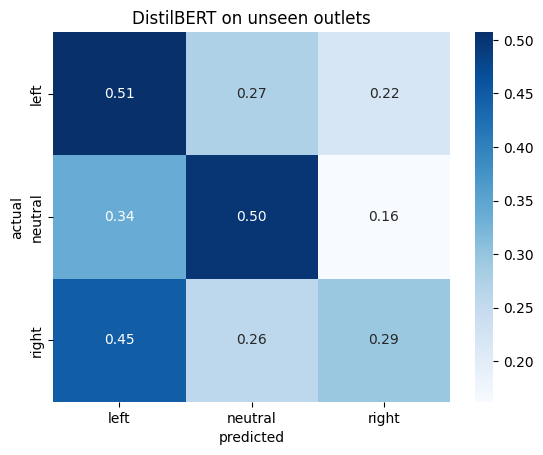

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(true_ids, pred_ids, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("DistilBERT on unseen outlets")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
rs_train, rs_test = train_test_split(data, test_size=0.25, stratify=data["label"], random_state=42)
rs_tr, rs_va = train_test_split(rs_train, test_size=0.15, stratify=rs_train["label"], random_state=42)

rs_train_ds = to_ds(rs_tr.reset_index(drop=True))
rs_val_ds = to_ds(rs_va.reset_index(drop=True))
rs_test_ds = to_ds(rs_test.reset_index(drop=True))

# class weights for this split (the trainer reads the global `weights`)
y_rs = np.array([label2id[l] for l in rs_tr["label"]])
w = compute_class_weight("balanced", classes=np.arange(3), y=y_rs)
weights = torch.tensor(w, dtype=torch.float).to("cuda")

model_rs = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=3, id2label=id2label, label2id=label2id
)

args_rs = TrainingArguments(
    output_dir="bias_model_random",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    report_to="none",
)

trainer_rs = WeightedTrainer(
    model=model_rs, args=args_rs,
    train_dataset=rs_train_ds, eval_dataset=rs_val_ds,
    data_collator=collator, compute_metrics=metrics,
)
trainer_rs.train()

out_rs = trainer_rs.predict(rs_test_ds)
rs_pred = out_rs.predictions.argmax(axis=1)
print(classification_report(out_rs.label_ids, rs_pred, target_names=labels))
print("random split macro F1:", round(f1_score(out_rs.label_ids, rs_pred, average="macro"), 3))

Map:   0%|          | 0/6900 [00:00<?, ? examples/s]

Map:   0%|          | 0/1218 [00:00<?, ? examples/s]

Map:   0%|          | 0/2707 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.016082,0.427457
2,No log,1.005072,0.467590
3,0.994804,1.036000,0.474805


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

        left       0.55      0.44      0.49      1220
     neutral       0.26      0.49      0.34       370
       right       0.56      0.51      0.53      1117

    accuracy                           0.48      2707
   macro avg       0.46      0.48      0.46      2707
weighted avg       0.52      0.48      0.49      2707

random split macro F1: 0.456
